In [1]:
import os
import pandas as pd
import numpy as np

# Fix random seed for total reproducibility
SEED = 42

# Automatically locate train.csv and test.csv in any Kaggle input directory
train_path, test_path = None, None
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        if filename == 'train.csv' and not train_path:
            train_path = os.path.join(dirname, filename)
        elif filename == 'test.csv' and not test_path:
            test_path = os.path.join(dirname, filename)

# Fallback to standard paths if not found via walk
train_path = train_path or '/kaggle/input/train.csv'
test_path = test_path or '/kaggle/input/test.csv'

# Load datasets
train_df = pd.read_csv(train_path)
test_df = pd.read_csv(test_path)

print(f"Train Shape: {train_df.shape}")
print(f"Test Shape: {test_df.shape}")

# Preview data types and missing values
print("\nTrain Data Info:")
train_df.info()
display(train_df.head())
print("Train columns:", train_df.columns.tolist())

Train Shape: (8000, 17)
Test Shape: (2000, 17)

Train Data Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8000 entries, 0 to 7999
Data columns (total 17 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   VendorID               8000 non-null   int64  
 1   tpep_pickup_datetime   8000 non-null   object 
 2   tpep_dropoff_datetime  8000 non-null   object 
 3   passenger_count        7710 non-null   float64
 4   trip_distance          8000 non-null   float64
 5   RatecodeID             7710 non-null   float64
 6   store_and_fwd_flag     7710 non-null   object 
 7   PULocationID           8000 non-null   int64  
 8   DOLocationID           8000 non-null   int64  
 9   payment_type           8000 non-null   object 
 10  extra                  8000 non-null   float64
 11  tip_amount             8000 non-null   float64
 12  tolls_amount           8000 non-null   float64
 13  improvement_surcharge  8000 non-null   floa

,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,extra,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee
0,1,2023-06-29 19:30:24,2023-06-29 18:24:35,1.0,1.45,1.0,N,58,82,Credit Card,2.5,8.105869,0.0,1.0,25.68,2.5,0.0
1,1,2023-06-28 16:52:43,2023-06-28 17:20:05,6.0,0.98,1.0,N,253,153,Cash,2.5,0.570916,0.0,1.0,15.10,2.5,0.0
2,0,2023-06-30 06:03:32,2023-06-30 05:53:56,1.0,0.40,1.0,N,85,264,Credit Card,2.5,4.616720,0.0,1.0,10.40,2.5,0.0
3,1,2023-06-30 14:09:29,2023-06-30 13:07:32,1.0,0.85,1.0,N,2,139,Credit Card,0.0,3.380739,0.0,1.0,12.32,2.5,0.0
4,1,2023-06-30 00:35:04,2023-06-29 23:44:36,NaN,4.59,NaN,NaN,12,99,Wallet,0.0,1.534365,0.0,1.0,27.56,NaN,NaN


Train columns: ['VendorID', 'tpep_pickup_datetime', 'tpep_dropoff_datetime', 'passenger_count', 'trip_distance', 'RatecodeID', 'store_and_fwd_flag', 'PULocationID', 'DOLocationID', 'payment_type', 'extra', 'tip_amount', 'tolls_amount', 'improvement_surcharge', 'total_amount', 'congestion_surcharge', 'Airport_fee']


In [2]:
import os
import pandas as pd
import numpy as np
import lightgbm as lgb
from sklearn.model_selection import KFold
from sklearn.metrics import mean_squared_error  # <--- THIS WAS MISSING!

# 1. BULLETPROOF ADVANCED FEATURE ENGINEERING PIPELINE
def advanced_feature_engineering(df, is_train=True, train_route_freq=None):
    df = df.copy()
    
    if is_train:
        # Data Hygiene: Remove zero/negative values & extreme outliers
        if 'total_amount' in df.columns:
            df = df[df['total_amount'] > 0].reset_index(drop=True)
            fare_cap = df['total_amount'].quantile(0.999)
            df = df[df['total_amount'] <= fare_cap].reset_index(drop=True)
        if 'trip_distance' in df.columns:
            df = df[df['trip_distance'] > 0].reset_index(drop=True)

    # Find pickup and dropoff datetime columns dynamically
    pickup_col = next((col for col in ['pickup_datetime', 'tpep_pickup_datetime'] if col in df.columns), None)
    dropoff_col = next((col for col in ['dropoff_datetime', 'tpep_dropoff_datetime'] if col in df.columns), None)
    
    if pickup_col:
        df[pickup_col] = pd.to_datetime(df[pickup_col])
        df['hour'] = df[pickup_col].dt.hour
        df['dayofweek'] = df[pickup_col].dt.dayofweek
        df['month'] = df[pickup_col].dt.month
        df['is_weekend'] = df['dayofweek'].isin([5, 6]).astype(int)
        df['is_rush_hour'] = ((~df['is_weekend'].astype(bool)) & ((df['hour'].between(8, 10)) | (df['hour'].between(17, 20)))).astype(int)

    # Physics & Speed Features (Only calculated if dropoff column exists)
    if pickup_col and dropoff_col:
        df[dropoff_col] = pd.to_datetime(df[dropoff_col])
        df['trip_duration_min'] = (df[dropoff_col] - df[pickup_col]).dt.total_seconds() / 60.0
        df['speed_mph'] = df['trip_distance'] / ((df['trip_duration_min'] / 60.0) + 1e-5)
        df['distance_per_min'] = df['trip_distance'] / (df['trip_duration_min'] + 1e-5)

    # Surcharges Sum
    surcharge_cols = ['extra', 'tolls_amount', 'improvement_surcharge', 'congestion_surcharge', 'Airport_fee']
    existing_surcharges = [col for col in surcharge_cols if col in df.columns]
    if existing_surcharges:
        df['total_surcharges'] = df[existing_surcharges].sum(axis=1)

    # Route Pairing & Frequency Encoding
    if 'PULocationID' in df.columns and 'DOLocationID' in df.columns:
        df['route_pair'] = df['PULocationID'].astype(str) + "_" + df['DOLocationID'].astype(str)
        
        if is_train:
            route_freq = df['route_pair'].value_counts().to_dict()
            df['route_freq'] = df['route_pair'].map(route_freq).fillna(1)
        else:
            route_freq = train_route_freq if train_route_freq is not None else {}
            df['route_freq'] = df['route_pair'].map(route_freq).fillna(1)
            
        df = df.drop(columns=['route_pair'], errors='ignore')

    return df, (route_freq if is_train else None)

# Apply to Train and Test (Assuming train_df and test_df are loaded from your previous cell)
train_clean, train_route_freq = advanced_feature_engineering(train_df, is_train=True)
test_clean, _ = advanced_feature_engineering(test_df, is_train=False, train_route_freq=train_route_freq)

print(f"Advanced Train Shape: {train_clean.shape}")
print(f"Advanced Test Shape: {test_clean.shape}")

# 2. TRAINING & VALIDATION PIPELINE
target = 'total_amount'
exclude_cols = [target, 'id', 'pickup_datetime', 'dropoff_datetime', 'tpep_pickup_datetime', 'tpep_dropoff_datetime']

train_numeric = train_clean.select_dtypes(include=[np.number]).columns.tolist()
test_numeric = test_clean.select_dtypes(include=[np.number]).columns.tolist()
features = [col for col in train_numeric if col in test_numeric and col not in exclude_cols]

print(f"\nTraining using {len(features)} advanced features: {features}")

X = train_clean[features].astype(np.float32)
y = train_clean[target].astype(np.float32)
X_test = test_clean[features].astype(np.float32)

SEED = 42
kf = KFold(n_splits=5, shuffle=True, random_state=SEED)

oof_preds = np.zeros(len(X))
test_preds = np.zeros(len(X_test))

for fold, (train_idx, val_idx) in enumerate(kf.split(X, y)):
    X_train, y_train = X.iloc[train_idx], y.iloc[train_idx]
    X_val, y_val = X.iloc[val_idx], y.iloc[val_idx]
    
    model = lgb.LGBMRegressor(
        n_estimators=1500,
        learning_rate=0.03,
        num_leaves=31,
        random_state=SEED,
        verbose=-1
    )
    
    model.fit(
        X_train, y_train,
        eval_set=[(X_val, y_val)],
        callbacks=[lgb.early_stopping(stopping_rounds=50, verbose=False)]
    )
    
    oof_preds[val_idx] = model.predict(X_val)
    test_preds += model.predict(X_test) / kf.n_splits

cv_rmse = np.sqrt(mean_squared_error(y, oof_preds))
print(f"\nNew Upgraded Out-of-Fold RMSE: {cv_rmse:.4f}")

# 3. GENERATE SUBMISSION FILE FOR KAGGLE
id_col = 'id' if 'id' in test_clean.columns else test_clean.columns[0]
submission = pd.DataFrame({
    id_col: test_clean[id_col],
    'total_amount': test_preds
})

# Save as submission.csv in the working directory
submission.to_csv('submission.csv', index=False)
print("\nSubmission file 'submission.csv' generated successfully!")
display(submission.head())

Advanced Train Shape: (7798, 27)
Advanced Test Shape: (2000, 27)

Training using 22 advanced features: ['VendorID', 'passenger_count', 'trip_distance', 'RatecodeID', 'PULocationID', 'DOLocationID', 'extra', 'tip_amount', 'tolls_amount', 'improvement_surcharge', 'congestion_surcharge', 'Airport_fee', 'hour', 'dayofweek', 'month', 'is_weekend', 'is_rush_hour', 'trip_duration_min', 'speed_mph', 'distance_per_min', 'total_surcharges', 'route_freq']

New Upgraded Out-of-Fold RMSE: 4.7718

Submission file 'submission.csv' generated successfully!


,id,total_amount
0,0,31.580994
1,1,11.447715
2,2,20.652482
3,3,20.658097
4,4,21.135362


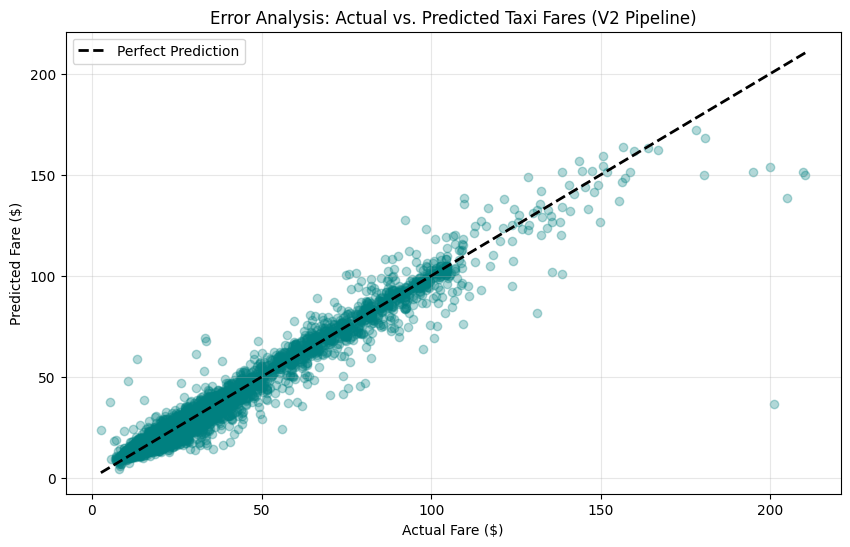

Mean Error / Bias: 0.0254
Mean Absolute Error (MAE): 2.6513


In [3]:
import matplotlib.pyplot as plt

# Calculate Residuals (Errors)
residuals = y - oof_preds

# Plot Actual vs Predicted Fares
plt.figure(figsize=(10, 6))
plt.scatter(y, oof_preds, alpha=0.3, color='teal')
plt.plot([y.min(), y.max()], [y.min(), y.max()], 'k--', lw=2, label='Perfect Prediction')
plt.xlabel('Actual Fare ($)')
plt.ylabel('Predicted Fare ($)')
plt.title('Error Analysis: Actual vs. Predicted Taxi Fares (V2 Pipeline)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

print(f"Mean Error / Bias: {residuals.mean():.4f}")
print(f"Mean Absolute Error (MAE): {np.abs(residuals).mean():.4f}")